# 04 - Interpretasi dengan SHAP
SHAP menjelaskan prediksi model dengan membagi selisih antara prediksi tiap nasabah dan prediksi rata-rata ke dalam kontribusi tiap fitur.
- **Global**: fitur mana yang paling berpengaruh dan ke arah mana.
- **Lokal**: kenapa nasabah tertentu dinilai berisiko tinggi atau rendah.

Nilai SHAP untuk model LightGBM ini ada dalam skala **log-odds**. Nilai positif menaikkan risiko gagal bayar, negatif menurunkannya.
Dihitung pada sampel dari **test set** dengan model final (`models/lgbm_final.joblib`).

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yml").exists())
sys.path.append(str(ROOT))

from src.data import load_model_table, prepare, split

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
REPORTS_DIR = ROOT / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

SAMPLE_SIZE = 10000   # jumlah nasabah test yang dijelaskan; turunkan kalau terlalu lama

model = joblib.load(ROOT / "models" / "lgbm_final.joblib")
X, y = prepare(load_model_table())
X_train, X_valid, X_test, y_train, y_valid, y_test = split(X, y)

X_sample = X_test.sample(n=min(SAMPLE_SIZE, len(X_test)), random_state=42)
y_sample = y_test.loc[X_sample.index]
print(X_sample.shape, f"gagal bayar {y_sample.mean() * 100:.2f}%")

(10000, 165) gagal bayar 8.58%


## 1. Hitung nilai SHAP

In [2]:
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_sample)
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]
values = np.asarray(sv)
expected_value = float(np.atleast_1d(explainer.expected_value)[-1])

# Cek: nilai dasar + jumlah kontribusi harus sama dengan prediksi mentah model
raw = model.predict(X_sample, raw_score=True)
print("Selisih maksimum rekonstruksi:", float(np.abs(values.sum(axis=1) + expected_value - raw).max()))

# Untuk grafik, kolom kategori diubah ke kode angka (hanya untuk pewarnaan)
X_plot = X_sample.copy()
cat_features = [c for c in X_plot.columns if str(X_plot[c].dtype) == "category"]
for col in cat_features:
    X_plot[col] = X_plot[col].cat.codes.replace(-1, np.nan)
print("Kolom kategori:", len(cat_features))

Selisih maksimum rekonstruksi: 2.4868995751603507e-14
Kolom kategori: 12


## 2. Fitur terpenting secara global
Rata-rata nilai mutlak SHAP (batang) dan sebaran pengaruhnya (beeswarm). Pada beeswarm, tiap titik adalah satu nasabah; warna menunjukkan nilai fitur (merah = tinggi), posisi horizontal menunjukkan pengaruh terhadap risiko.
Untuk kolom kategori, warna memakai kode angka kategori sehingga tidak bermakna; baca batang pentingnya saja.

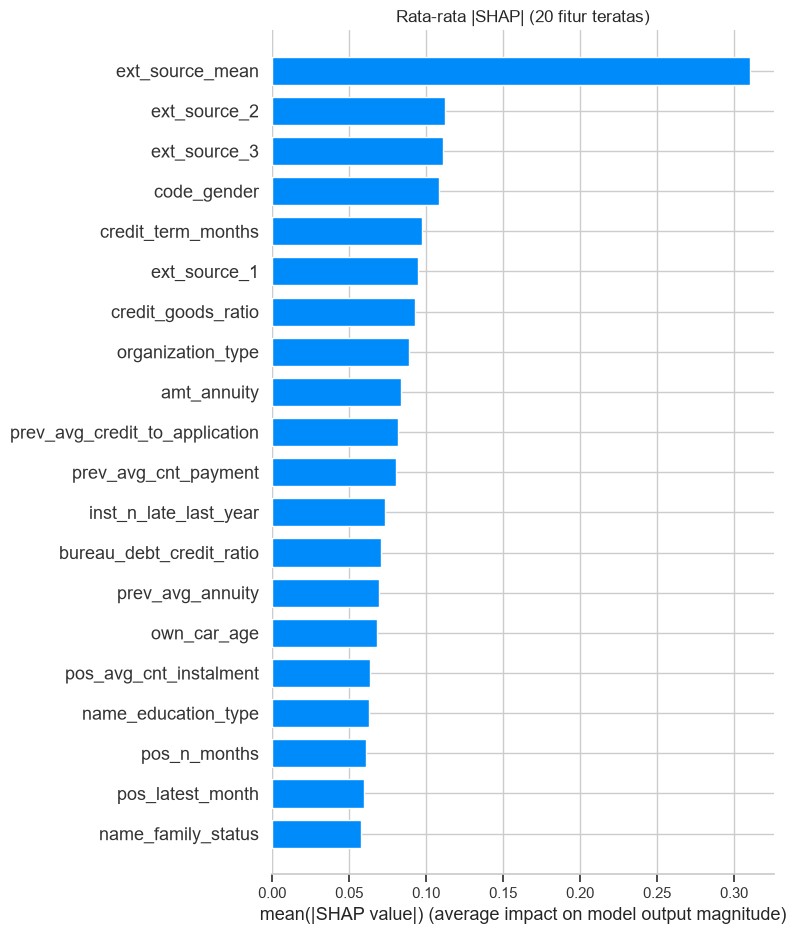

In [3]:
shap.summary_plot(values, X_plot, plot_type="bar", max_display=20, show=False)
plt.title("Rata-rata |SHAP| (20 fitur teratas)")
plt.tight_layout()
plt.show()

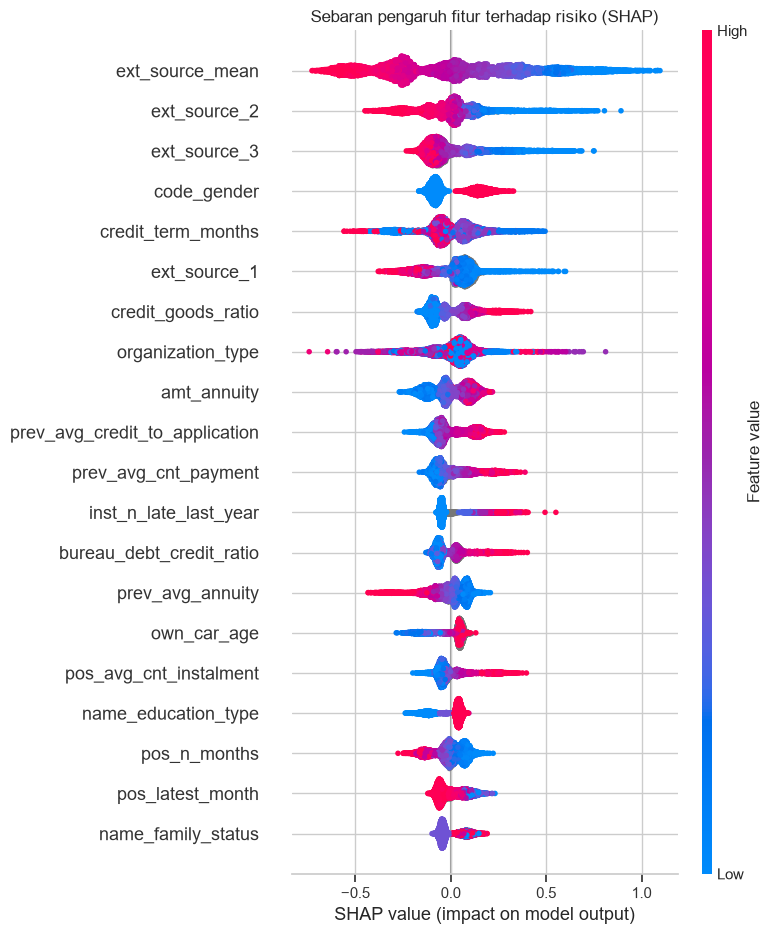

In [4]:
shap.summary_plot(values, X_plot, max_display=20, show=False)
plt.title("Sebaran pengaruh fitur terhadap risiko (SHAP)")
plt.tight_layout()
plt.show()

## 3. Tabel ringkas: besar dan arah pengaruh
`arah` dihitung dari korelasi Spearman antara nilai fitur dan nilai SHAP-nya: apakah nilai yang lebih tinggi cenderung menaikkan atau menurunkan risiko.

In [5]:
mean_abs = pd.Series(np.abs(values).mean(axis=0), index=X_plot.columns)

def direction(col):
    if col in cat_features:
        return "kategori"
    corr = X_plot[col].corr(pd.Series(values[:, X_plot.columns.get_loc(col)], index=X_plot.index), method="spearman")
    if pd.isna(corr) or abs(corr) < 0.1:
        return "lemah / tidak monoton"
    return "nilai tinggi -> risiko naik" if corr > 0 else "nilai tinggi -> risiko turun"

importance = (pd.DataFrame({"mean_abs_shap": mean_abs})
              .assign(persen=lambda d: (d["mean_abs_shap"] / d["mean_abs_shap"].sum() * 100).round(2))
              .sort_values("mean_abs_shap", ascending=False))
importance["arah"] = [direction(c) for c in importance.index]
importance["mean_abs_shap"] = importance["mean_abs_shap"].round(4)
importance.to_csv(REPORTS_DIR / "shap_importance.csv")
importance.head(20)

,mean_abs_shap,persen,arah
ext_source_mean,0.3104,8.42,nilai tinggi -> risiko turun
ext_source_2,0.1122,3.04,nilai tinggi -> risiko turun
ext_source_3,0.1108,3.00,nilai tinggi -> risiko turun
code_gender,0.1081,2.93,kategori
credit_term_months,0.0976,2.65,nilai tinggi -> risiko turun
ext_source_1,0.0949,2.58,nilai tinggi -> risiko turun
credit_goods_ratio,0.0929,2.52,nilai tinggi -> risiko naik
organization_type,0.0888,2.41,kategori
amt_annuity,0.0835,2.26,nilai tinggi -> risiko naik
prev_avg_credit_to_application,0.0815,2.21,nilai tinggi -> risiko naik


## 4. Pengaruh per sumber data
Apakah fitur dari tabel selain aplikasi (bureau, riwayat cicilan, dst.) benar-benar menyumbang prediksi?

Aplikasi (termasuk turunan)    41.1
Skor eksternal                 17.0
Previous application           12.5
Installments                   10.4
Bureau                         10.0
POS cash                        5.6
Kartu kredit                    3.4


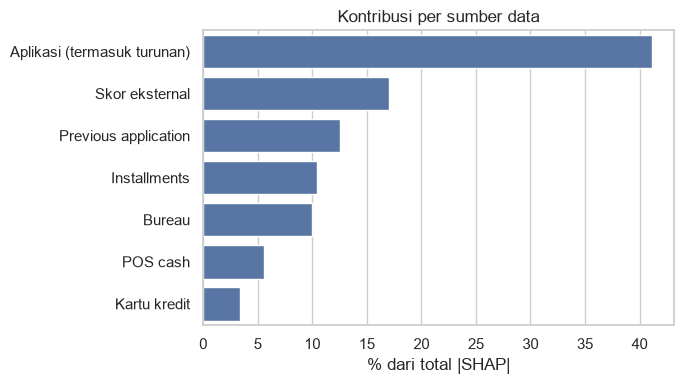

In [6]:
def source_group(name):
    if name.startswith("ext_source"):
        return "Skor eksternal"
    for prefix, label in [("bureau_", "Bureau"), ("prev_", "Previous application"),
                          ("pos_", "POS cash"), ("inst_", "Installments"), ("cc_", "Kartu kredit")]:
        if name.startswith(prefix):
            return label
    return "Aplikasi (termasuk turunan)"

by_source = (mean_abs.groupby(mean_abs.index.map(source_group)).sum()
             .sort_values(ascending=False))
share = (by_source / by_source.sum() * 100).round(1)
print(share.to_string())

plt.figure(figsize=(7, 4))
sns.barplot(x=share.values, y=share.index, color="#4c72b0")
plt.xlabel("% dari total |SHAP|")
plt.ylabel("")
plt.title("Kontribusi per sumber data")
plt.tight_layout()
plt.show()

## 5. Hubungan nilai fitur dan pengaruhnya (3 fitur numerik teratas)

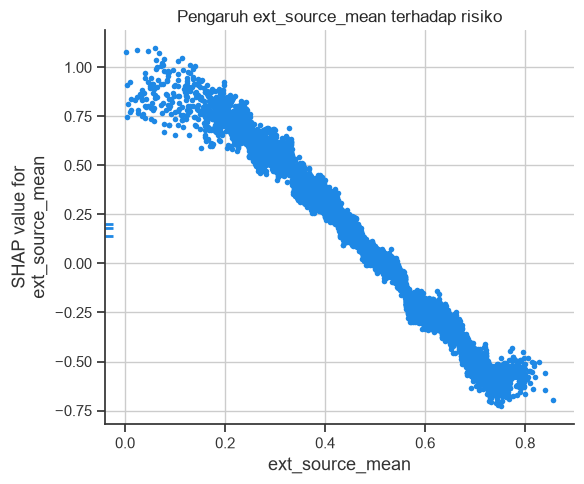

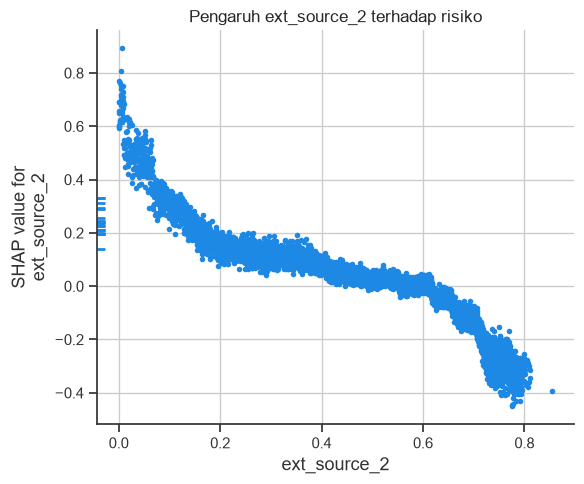

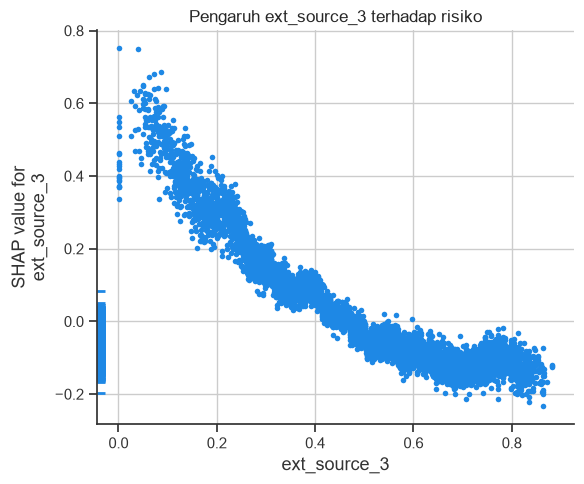

In [7]:
top_numeric = [c for c in importance.index if c not in cat_features][:3]
for col in top_numeric:
    shap.dependence_plot(col, values, X_plot, interaction_index=None, show=False)
    plt.title(f"Pengaruh {col} terhadap risiko")
    plt.tight_layout()
    plt.show()

## 6. Penjelasan per nasabah
Tiga contoh dari sampel test: risiko prediksi tertinggi, menengah, dan terendah. Grafik waterfall menunjukkan fitur yang mendorong risiko naik (merah) dan turun (biru) dari nilai dasar.

Risiko tertinggi: prediksi gagal bayar 76.5%, aktual = 1


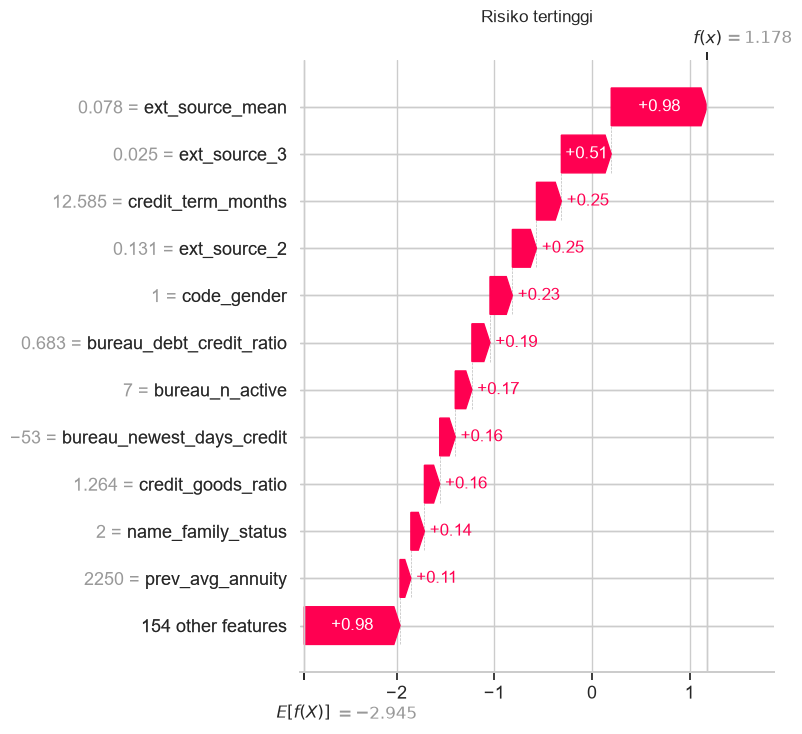

Risiko menengah: prediksi gagal bayar 4.6%, aktual = 0


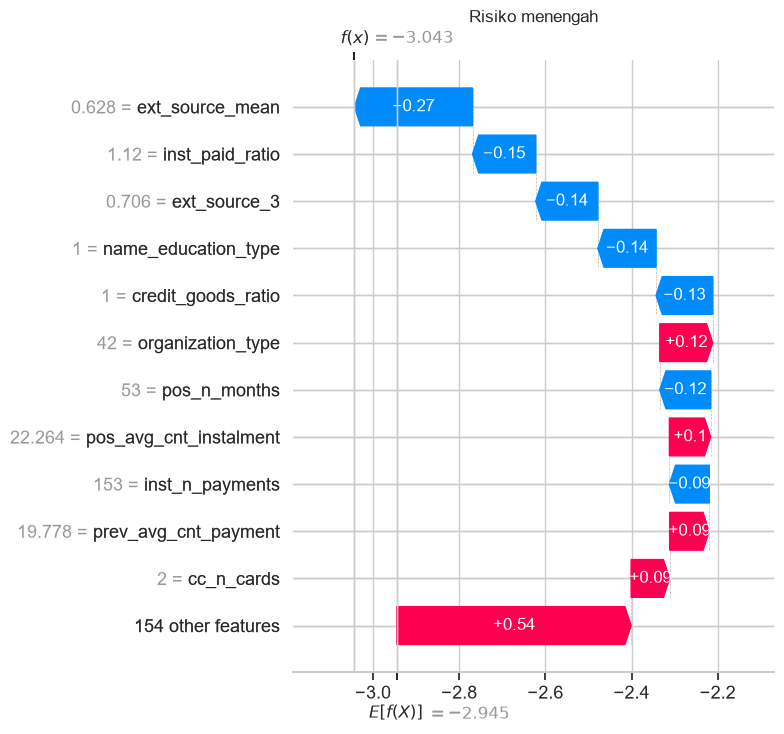

Risiko terendah: prediksi gagal bayar 0.1%, aktual = 0


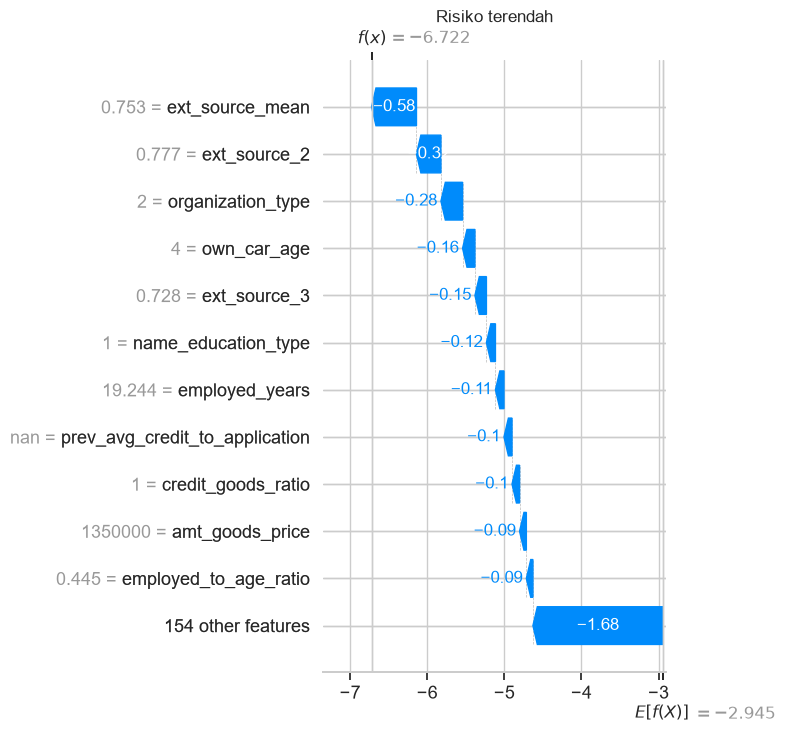

In [8]:
proba = model.predict_proba(X_sample)[:, 1]
order = np.argsort(proba)
picks = {"Risiko tertinggi": order[-1], "Risiko menengah": order[len(order) // 2], "Risiko terendah": order[0]}

for title, i in picks.items():
    print(f"{title}: prediksi gagal bayar {proba[i] * 100:.1f}%, aktual = {int(y_sample.iloc[i])}")
    explanation = shap.Explanation(values=values[i], base_values=expected_value,
                                   data=X_plot.iloc[i].values, feature_names=list(X_plot.columns))
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(title)
    plt.tight_layout()
    plt.show()

## Catatan temuan
- **Skor eksternal paling dominan:** ext_source_mean (8,4% dari total |SHAP|) dan ext_source_1/2/3
  (gabungan 17,0%). Skor tinggi menurunkan risiko; ext_source_mean hampir linear, ext_source_2
  melonjak hanya pada skor sangat rendah (<0,1), ext_source_3 menurun curam sampai ~0,5.
- **Beban cicilan:** annuity tinggi dan tenor pendek (credit_term_months rendah) menaikkan risiko;
  credit_goods_ratio tinggi (kredit melebihi harga barang) juga menaikkan risiko.
- **Perilaku pembayaran dan utang eksternal:** jumlah cicilan telat setahun terakhir
  (inst_n_late_last_year) dan rasio utang di bureau (bureau_debt_credit_ratio) yang tinggi
  menaikkan risiko.
- **Kontribusi per sumber data:** aplikasi (termasuk fitur turunan) 41,1%, skor eksternal 17,0%,
  previous_application 12,5%, installments 10,4%, bureau 10,0%, POS cash 5,6%, kartu kredit 3,4%.
  Sekitar 42% pengaruh berasal dari fitur agregat lima tabel selain aplikasi.
- **Gain vs SHAP:** importance gain di notebook 02 tampak didominasi satu fitur; SHAP menunjukkan
  pengaruh yang lebih tersebar dan peringkat yang berbeda.
- **Contoh lokal:** nasabah risiko tertinggi (76,5%) didorong skor eksternal sangat rendah, tenor
  pendek, dan banyak kredit aktif di bureau; nasabah risiko terendah (0,1%) memiliki skor
  eksternal tinggi, mobil baru, dan masa kerja panjang.
- **Catatan:** SHAP menjelaskan perilaku model, bukan sebab-akibat. ext_source_mean turunan dari
  tiga skor lain sehingga pengaruhnya terbagi di antaranya. code_gender masuk 5 besar dan perlu
  ditinjau dari sisi keadilan.